# 多受试者 Udeco2 / Udeco3 自适应状态分析

目标：按自然平台分别识别 Udeco2、Udeco3 的 H/M/L 状态，保留 100–200 ms 短状态，校正慢变 M(t)，并输出可追溯的验证图、批量统计和 Excel。

成功标准：单文件图可肉眼检查状态；批处理与绘图调用同一 `classify_udeco`；坏样本只记录 QC、不阻断其他样本。

In [12]:
# Cell 1 - Import：只导入本项目唯一算法模块
from __future__ import annotations

import os
import platform
from dataclasses import asdict
from pathlib import Path

%matplotlib widget
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from udeco_analysis import (
    AnalysisConfig,
    analyze_all_subjects,
    analyze_sample,
    export_batch_figures,
    export_excel,
    load_udeco_sample,
    plot_validation,
    select_validation_candidates,
)

print(f'Python: {platform.python_version()} | 工作目录: {Path.cwd()}')

Python: 3.10.20 | 工作目录: d:\MHLcode


## 用户参数区

所有时间量均使用秒，并在算法内部按采样率换算为采样点。先修改路径；第一轮只运行 Validation，人工确认后再把 `RUN_BATCH` 改为 `True`。

In [13]:
# Cell 2 - User configuration
DATA_ROOT = Path(os.environ.get('UDECO_DATA_ROOT', 'D:\\MHLcode\\subject_data'))
SUBJECTS = ['ts', 'lyx', 'lzj', 'cgx', 'pjy', 'hjy']

# 原始采样率：change6/Pydisplay 协议固定 100 Hz；改变后所有秒参数自动换算。
FS_HZ = 100

# 轻度中值滤波：增大更抗尖峰但更易钝化短状态；减小更保真但更敏感。建议 0.01–0.03 s。
MEDIAN_FILTER_SEC = 0.03
# 初始 M 锚定时长：增大估计更稳但更可能混入后续状态；减小更局部但噪声更大。协议默认 30 s。
INITIAL_M_SEC = 30.0
# 变化点左右中位数窗口：增大更稳但可能吞短平台；减小更灵敏。建议 0.02–0.04 s。
CHANGE_WINDOW_SEC = 0.03
# 变化点噪声倍率：增大减少误检；减小可发现较小阶跃但会增加切段。建议 4–7。
CHANGE_THRESHOLD_SIGMA = 5.0
# 相邻峰合并距离：增大可合并同一阶跃周围峰；过大会合并短状态两端。建议 0.02–0.05 s。
CHANGE_PEAK_MERGE_SEC = 0.04
STEP_LOCAL_WINDOW_SEC = 0.30
STEP_MAX_TRANSITION_SEC = 0.08
STEP_STABILITY_SIGMA = 3.0
# 极短异常参考：增大更能抑制尖峰但可能丢短状态；减小更保守。建议 0.04–0.08 s。
MIN_PLATFORM_SEC = 0.06
# 初始状态中心分离倍率：增大更难新增 H/L；减小更易把波动当状态。建议 3–6。
STATE_SEPARATION_SIGMA = 4.0
# 可信 M anchor 残差倍率：增大能跟踪更大漂移但可能吸收 H/L；减小更纯但 anchor 更少。建议 2–3。
M_ANCHOR_SIGMA = 2.5
# M(t) 平滑尺度：增大基线更慢、更不跟随短状态；减小更能跟漂移但可能追随阶跃。建议 5–20 s。
M_BASELINE_SMOOTH_SEC = 10.0
# M anchor 最大迭代轮数：增大可逐步覆盖更大漂移但耗时增加；建议 3–7。
M_BASELINE_MAX_ITER = 5
# 进入 H/L 的 sigma 倍率：增大更保守；减小更灵敏。必须大于 EXIT_SIGMA，建议 3.5–6。
ENTER_SIGMA = 4.0
# 退出 H/L 的 sigma 倍率：增大更早退出，减小滞回更强。建议 1.5–3。
EXIT_SIGMA = 2.0
# 可选 GMM/BIC：True 时只辅助 segment center；默认 False 保持透明可解释。
USE_GMM = False

# 运动检测：沿用 change6 的 ACC 规则；窗口增大更稳但边界更钝，连续窗增大更保守。
MOTION_CALIBRATION_SEC = 30.0
MOTION_WINDOW_SEC = 8.0
MOTION_STEP_SEC = 1.0
MOTION_THRESHOLD_SIGMA = 3.0
MOTION_TRANSITION_WINDOWS = 6

# 单文件验证：也可设置环境变量 UDECO_VALIDATION_FILE；留空时相关 cell 安全跳过。
_validation_text = os.environ.get('UDECO_VALIDATION_FILE', '').strip()
# VALIDATION_FILE = Path(_validation_text) if _validation_text else None
VALIDATION_FILE = DATA_ROOT / "ts" / "ts_write_1_sensor.csv"
SHOW_DEBUG_INFO = True

# 批量开关：Validation 人工确认前保持 False；True 时分析 SUBJECTS 并写 Excel。
RUN_BATCH = True
OUTPUT_ROOT = Path(os.environ.get('UDECO_OUTPUT_ROOT', 'outputs'))
OUTPUT_EXCEL = Path(os.environ.get(
    'UDECO_OUTPUT_EXCEL', str(OUTPUT_ROOT / 'udeco_state_results.xlsx')
))

## 算法与输入契约

读取严格配对的 `{subject}_{motion}_{index}_sensor.csv` / `_HRdata.csv`；共享标定为 `DATA_ROOT/ck.mat`。公式为 `Udeco2=(Uh2-Uc2)/(c2-Uc2)`、`Udeco3=(Uh3-Uc3)/(c3-Uc3)`。

主流程：轻度 median → M0/MAD → 短窗变化点 → 自然 segments → 迭代 M(t) → residual → segment 级 hysteresis → 样本标签与统计。

In [14]:
# Cell 3 - 将用户参数集中封装；模块内部不再散落 magic numbers
CONFIG = AnalysisConfig(
    median_filter_sec=MEDIAN_FILTER_SEC,
    initial_m_sec=INITIAL_M_SEC,
    change_window_sec=CHANGE_WINDOW_SEC,
    change_threshold_sigma=CHANGE_THRESHOLD_SIGMA,
    change_peak_merge_sec=CHANGE_PEAK_MERGE_SEC,
    step_local_window_sec=STEP_LOCAL_WINDOW_SEC,
    step_max_transition_sec=STEP_MAX_TRANSITION_SEC,
    step_stability_sigma=STEP_STABILITY_SIGMA,
    min_platform_sec=MIN_PLATFORM_SEC,
    state_separation_sigma=STATE_SEPARATION_SIGMA,
    m_anchor_sigma=M_ANCHOR_SIGMA,
    m_baseline_smooth_sec=M_BASELINE_SMOOTH_SEC,
    m_baseline_max_iter=M_BASELINE_MAX_ITER,
    enter_sigma=ENTER_SIGMA,
    exit_sigma=EXIT_SIGMA,
    use_gmm=USE_GMM,
    motion_calibration_sec=MOTION_CALIBRATION_SEC,
    motion_window_sec=MOTION_WINDOW_SEC,
    motion_step_sec=MOTION_STEP_SEC,
    motion_threshold_sigma=MOTION_THRESHOLD_SIGMA,
    motion_transition_windows=MOTION_TRANSITION_WINDOWS,
)
display(pd.Series(asdict(CONFIG), name='value').to_frame())

,value
median_filter_sec,0.03
initial_m_sec,30.0
change_window_sec,0.03
change_threshold_sigma,5.0
change_peak_merge_sec,0.04
step_local_window_sec,0.3
step_max_transition_sec,0.08
step_stability_sigma,3.0
min_platform_sec,0.06
state_separation_sigma,4.0


## Step 1：确认单文件读取

本 cell 只核对时间轴、标定映射与序号/分母 QC，不执行分类。

In [15]:
validation_loaded = None
if VALIDATION_FILE is None:
    print('未设置 VALIDATION_FILE：跳过单文件读取检查。')
elif not VALIDATION_FILE.is_file():
    print(f'VALIDATION_FILE 不存在：{VALIDATION_FILE}')
else:
    validation_loaded = load_udeco_sample(VALIDATION_FILE, data_root=DATA_ROOT, fs=FS_HZ)
    display(pd.Series({
        'sample_name': validation_loaded.sample_name,
        'n_samples': len(validation_loaded.time_s),
        'duration_s': len(validation_loaded.time_s) / validation_loaded.fs,
        'fs_hz': validation_loaded.fs,
        'sequence_interpolated': int(validation_loaded.qc['InterpFlag'].sum()),
        'near_zero_denominator': int(validation_loaded.qc['ud_denominator_near_zero'].sum()),
    }, name='value').to_frame())

,value
sample_name,ts_write_1
n_samples,19515
duration_s,195.15
fs_hz,100
sequence_interpolated,0
near_zero_denominator,0


## Validation / Manual Inspection

修改 `VALIDATION_FILE` 后，只需重跑参数、CONFIG、本节三个 cell。主图始终为 Udeco2/Udeco3 两行，H/M/L 用背景状态带表示。

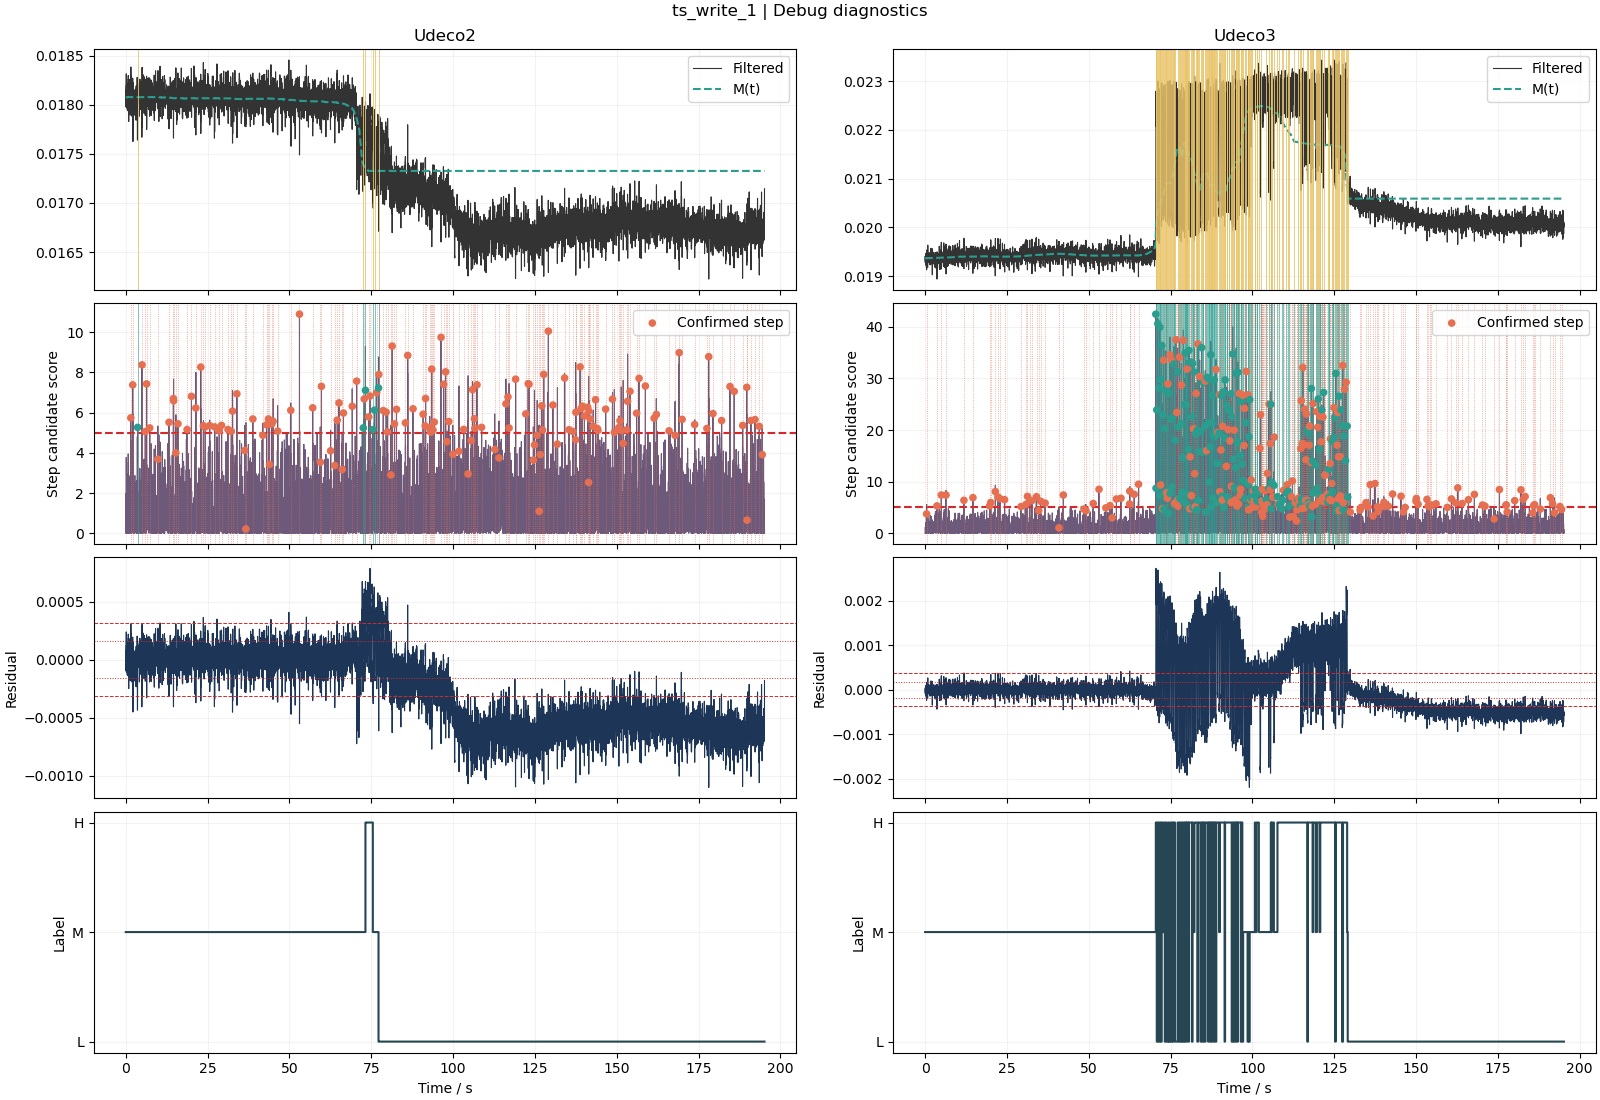

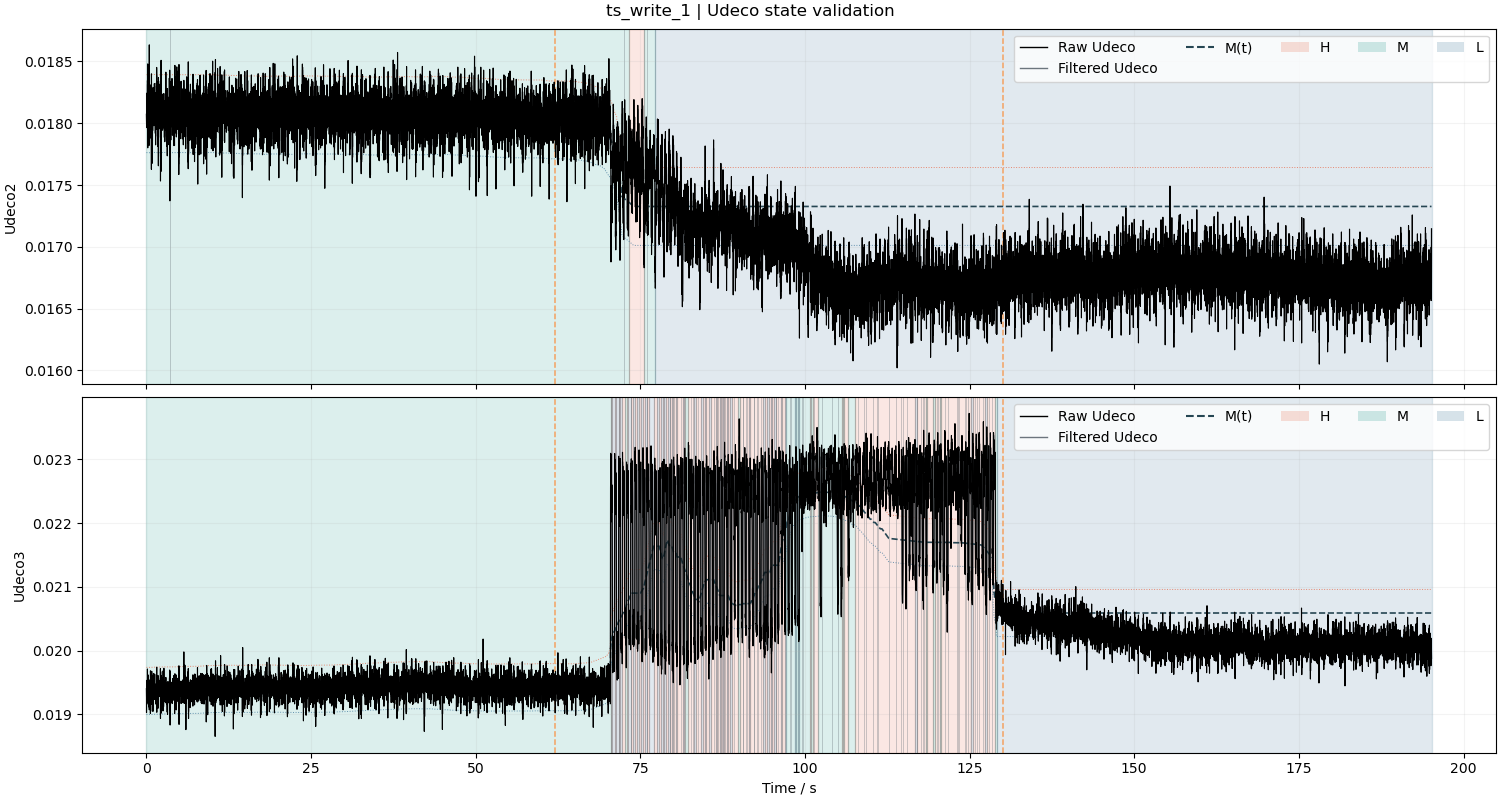

In [16]:
# Cell 4 - 单文件双通道完整分类与主/调试图
validation_result = None
validation_main_fig = None
validation_debug_fig = None
if VALIDATION_FILE is None or not VALIDATION_FILE.is_file():
    print('未提供可用 VALIDATION_FILE：Validation 安全跳过。')
else:
    validation_result = analyze_sample(VALIDATION_FILE, data_root=DATA_ROOT, fs=FS_HZ, config=CONFIG)
    validation_main_fig, validation_debug_fig = plot_validation(
        validation_result, show_debug_info=SHOW_DEBUG_INFO
    )
    plt.show()

### Validation 数值检查

同时检查最终统计、自然 segment、S(t)、M(t) 与 residual。若图形错误，先定位变化点、M(t)、中心判断还是滞回阈值。

In [17]:
if validation_result is not None:
    validation_stats = pd.DataFrame(
        [validation_result['channels'][name]['statistics'] for name in ('Udeco2', 'Udeco3')]
    )
    display(validation_stats)
    for channel_name in ('Udeco2', 'Udeco3'):
        print(f'--- {channel_name} segments ---')
        display(validation_result['channels'][channel_name]['segments'].head(30))
else:
    print('无 validation_result。')

,H_mean,H_std,H_total_duration,M_mean,M_std,M_total_duration,L_mean,L_std,L_total_duration,n_detected_states,...,sigma_M,state_separation,QC_flag,sample_name,subject,channel,analysis_status,error_message,motion_start_s,motion_end_s
0,0.017666,0.000247,2.25,0.018032,0.000195,74.97,0.016818,0.000243,117.93,3,...,0.000079,4.992613,OK,ts_write_1,ts,Udeco2,ok,,62.0,130.0
1,0.022384,0.000670,38.09,0.019788,0.000997,81.13,0.020248,0.000408,75.93,3,...,0.000092,4.897107,direct_H_to_L;direct_L_to_H,ts_write_1,ts,Udeco3,ok,,62.0,130.0


--- Udeco2 segments ---


,segment_id,start_idx,end_idx,start_time,end_time,duration,median,mean,std,MAD,filtered_median,initial_label,residual_median,trusted_m,final_label,platform_ok
0,0,0,362,0.00,3.62,3.62,0.018076,0.018072,0.000152,0.000072,0.018078,M,0.000000,True,M,True
1,1,362,7256,3.62,72.56,68.94,0.018055,0.018047,0.000168,0.000085,0.018055,M,0.000002,True,M,True
2,2,7256,7323,72.56,73.23,0.67,0.017665,0.017630,0.000280,0.000241,0.017665,L,0.000291,False,M,True
3,3,7323,7548,73.23,75.48,2.25,0.017720,0.017666,0.000247,0.000173,0.017722,L,0.000393,False,H,True
4,4,7548,7600,75.48,76.00,0.52,0.017350,0.017392,0.000298,0.000204,0.017321,L,-0.000006,True,M,True
5,5,7600,7722,76.00,77.22,1.22,0.017582,0.017533,0.000234,0.000164,0.017610,L,0.000284,False,M,True
6,6,7722,19515,77.22,195.15,117.93,0.016784,0.016818,0.000243,0.000137,0.016773,L,-0.000554,False,L,True


--- Udeco3 segments ---


,segment_id,start_idx,end_idx,start_time,end_time,duration,median,mean,std,MAD,filtered_median,initial_label,residual_median,trusted_m,final_label,platform_ok
0,0,0,7047,0.00,70.47,70.47,0.019418,0.019423,0.000144,0.000082,0.019417,M,-0.000002,True,M,True
1,1,7047,7054,70.47,70.54,0.07,0.022709,0.022750,0.000265,0.000155,0.022641,H,0.002579,False,H,True
2,2,7054,7076,70.54,70.76,0.22,0.022303,0.022218,0.000324,0.000145,0.022327,H,0.002141,False,H,True
3,3,7076,7108,70.76,71.08,0.32,0.019894,0.019887,0.000136,0.000093,0.019891,H,-0.000383,False,L,True
4,4,7108,7137,71.08,71.37,0.29,0.022432,0.022448,0.000380,0.000211,0.022418,H,0.002049,False,H,True
5,5,7137,7169,71.37,71.69,0.32,0.019936,0.019929,0.000164,0.000101,0.019952,H,-0.000473,False,L,True
6,6,7169,7177,71.69,71.77,0.08,0.022835,0.022684,0.000460,0.000077,0.022844,H,0.002381,False,H,True
7,7,7177,7197,71.77,71.97,0.20,0.022312,0.022380,0.000299,0.000173,0.022311,H,0.001841,False,H,True
8,8,7197,7227,71.97,72.27,0.30,0.020111,0.020147,0.000199,0.000067,0.020115,H,-0.000427,False,L,True
9,9,7227,7260,72.27,72.60,0.33,0.022363,0.022426,0.000354,0.000227,0.022297,H,0.001704,False,H,True


## 批量分析

仅在单文件图确认后设置 `RUN_BATCH=True`。Udeco2/Udeco3 独立分类；单样本错误保留为 NaN/QC 行，不阻断其余样本。

In [18]:
# Cell 5 - 全部受试者批量分析与图片输出
batch_results = {}
figure_report = pd.DataFrame()
batch_overview = pd.DataFrame()
if not RUN_BATCH:
    print('RUN_BATCH=False：跳过批量分析。')
else:
    batch_results = analyze_all_subjects(DATA_ROOT, SUBJECTS, fs=FS_HZ, config=CONFIG)
    figure_report = export_batch_figures(batch_results, OUTPUT_ROOT)
    display(figure_report)
    batch_overview = pd.DataFrame([
        {
            'subject': subject,
            'sample_channel_rows': len(result['sample_results']),
            'ok_rows': int((result['sample_results']['analysis_status'] == 'ok').sum()),
            'qc_rows': len(result['qc']),
        }
        for subject, result in batch_results.items()
    ])
    display(batch_overview)
    for subject, result in batch_results.items():
        print(f'=== {subject} ===')
        display(result['summary'])
        if not result['qc'].empty:
            display(result['qc'].head(20))

,subject,sample_name,figure_path,status,error_message
0,ts,ts_write_1,outputs\figures\ts\ts_write_1.png,ok,
1,ts,ts_write_2,outputs\figures\ts\ts_write_2.png,ok,
2,ts,ts_write_3,outputs\figures\ts\ts_write_3.png,ok,
3,ts,ts_write_4,outputs\figures\ts\ts_write_4.png,ok,
4,ts,ts_write_5,outputs\figures\ts\ts_write_5.png,ok,
...,...,...,...,...,...
94,hjy,hjy_rope_1,outputs\figures\hjy\hjy_rope_1.png,ok,
95,hjy,hjy_rope_2,outputs\figures\hjy\hjy_rope_2.png,ok,
96,hjy,hjy_rope_3,outputs\figures\hjy\hjy_rope_3.png,ok,
97,hjy,hjy_rope_4,outputs\figures\hjy\hjy_rope_4.png,ok,


,subject,sample_channel_rows,ok_rows,qc_rows
0,ts,36,36,0
1,lyx,30,30,0
2,lzj,30,30,0
3,cgx,38,38,0
4,pjy,32,32,0
5,hjy,32,32,0


=== ts ===


,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.020737,0.001579,14,0.0207369 ± 0.00157939
1,Udeco2,M,0.017735,0.001214,18,0.017735 ± 0.00121357
2,Udeco2,L,0.018453,0.001130,14,0.0184532 ± 0.00112959
3,Udeco3,H,0.026821,0.003000,15,0.0268212 ± 0.00299966
4,Udeco3,M,0.023824,0.002239,18,0.0238239 ± 0.00223928
5,Udeco3,L,0.023581,0.002489,15,0.0235806 ± 0.00248878


=== lyx ===


...

,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.021297,0.001716,16,0.0212966 ± 0.00171636
1,Udeco2,M,0.019200,0.001547,19,0.0192005 ± 0.00154723
2,Udeco2,L,0.019005,0.001362,16,0.0190047 ± 0.00136207
3,Udeco3,H,0.025461,0.003374,17,0.0254608 ± 0.00337406
4,Udeco3,M,0.022814,0.003576,19,0.0228144 ± 0.00357554
5,Udeco3,L,0.023140,0.003203,14,0.0231398 ± 0.00320254


=== pjy ===


,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.021698,0.001007,16,0.0216982 ± 0.00100688
1,Udeco2,M,0.018481,0.001024,16,0.0184813 ± 0.00102367
2,Udeco2,L,0.018721,0.000760,15,0.018721 ± 0.00076005
3,Udeco3,H,0.026099,0.006079,14,0.0260985 ± 0.00607897
4,Udeco3,M,0.022883,0.003954,16,0.0228828 ± 0.00395446
5,Udeco3,L,0.022567,0.004069,15,0.022567 ± 0.00406941


=== hjy ===


,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.022137,0.001771,12,0.0221375 ± 0.00177052
1,Udeco2,M,0.017129,0.000828,16,0.0171294 ± 0.00082761
2,Udeco2,L,0.018638,0.001746,11,0.0186379 ± 0.00174597
3,Udeco3,H,0.022022,0.000923,12,0.0220215 ± 0.000922856
4,Udeco3,M,0.020283,0.001505,16,0.0202834 ± 0.00150486
5,Udeco3,L,0.020612,0.001396,13,0.0206116 ± 0.00139605


## Excel 输出

每个受试者一个 sheet：Part A 为样本宽表，Part B 为受试者 H/M/L 汇总，Part C 为跳过文件与 QC。

In [19]:
# Cell 6 - Excel 仅在批处理结果存在时写出
excel_path = None
if batch_results:
    excel_path = export_excel(batch_results, OUTPUT_EXCEL)
    print(f'Excel 已输出：{excel_path.resolve()}')
else:
    print('无批处理结果：跳过 Excel。')

Excel 已输出：D:\MHLcode\outputs\udeco_state_results.xlsx


## 汇总检查

展示每个受试者 summary，并自动选择 M+H、M+L、最短非 M、最强运动、最大 M 漂移候选，供下一轮人工 Validation。

In [20]:
if batch_results:
    for subject, result in batch_results.items():
        print(f'=== {subject} ===')
        display(result['summary'])
        if not result['qc'].empty:
            display(result['qc'].head(20))
    validation_candidates = select_validation_candidates(batch_results)
    print('推荐人工复核样本：')
    display(validation_candidates)
else:
    print('无批处理结果可汇总。')

=== ts ===


,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.020737,0.001579,14,0.0207369 ± 0.00157939
1,Udeco2,M,0.017735,0.001214,18,0.017735 ± 0.00121357
2,Udeco2,L,0.018453,0.001130,14,0.0184532 ± 0.00112959
3,Udeco3,H,0.026821,0.003000,15,0.0268212 ± 0.00299966
4,Udeco3,M,0.023824,0.002239,18,0.0238239 ± 0.00223928
5,Udeco3,L,0.023581,0.002489,15,0.0235806 ± 0.00248878


=== lyx ===


,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.022587,0.002379,11,0.0225865 ± 0.00237946
1,Udeco2,M,0.019320,0.003017,15,0.0193204 ± 0.00301695
2,Udeco2,L,0.018672,0.002518,14,0.0186724 ± 0.00251819
3,Udeco3,H,0.031884,0.003389,14,0.0318838 ± 0.00338883
4,Udeco3,M,0.029410,0.003684,15,0.0294099 ± 0.00368403
5,Udeco3,L,0.027674,0.003304,11,0.0276736 ± 0.00330431


=== lzj ===


...

,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.021698,0.001007,16,0.0216982 ± 0.00100688
1,Udeco2,M,0.018481,0.001024,16,0.0184813 ± 0.00102367
2,Udeco2,L,0.018721,0.000760,15,0.018721 ± 0.00076005
3,Udeco3,H,0.026099,0.006079,14,0.0260985 ± 0.00607897
4,Udeco3,M,0.022883,0.003954,16,0.0228828 ± 0.00395446
5,Udeco3,L,0.022567,0.004069,15,0.022567 ± 0.00406941


=== hjy ===


,channel,state,mean,std,N,mean_std
0,Udeco2,H,0.022137,0.001771,12,0.0221375 ± 0.00177052
1,Udeco2,M,0.017129,0.000828,16,0.0171294 ± 0.00082761
2,Udeco2,L,0.018638,0.001746,11,0.0186379 ± 0.00174597
3,Udeco3,H,0.022022,0.000923,12,0.0220215 ± 0.000922856
4,Udeco3,M,0.020283,0.001505,16,0.0202834 ± 0.00150486
5,Udeco3,L,0.020612,0.001396,13,0.0206116 ± 0.00139605


推荐人工复核样本：


,category,subject,sample_name,channel,sensor_csv,score
0,M_plus_H,pjy,pjy_gripper_1,Udeco3,D:\MHLcode\subject_data\pjy\pjy_gripper_1_sens...,63.589025
1,M_plus_L,pjy,pjy_write_1,Udeco3,D:\MHLcode\subject_data\pjy\pjy_write_1_sensor...,42.136168
2,shortest_non_M,ts,ts_run_1,Udeco3,D:\MHLcode\subject_data\ts\ts_run_1_sensor.csv,0.050000
3,strongest_motion,hjy,hjy_rope_3,,D:\MHLcode\subject_data\hjy\hjy_rope_3_sensor.csv,0.375932
4,largest_M_drift,lzj,lzj_rope_4,Udeco3,D:\MHLcode\subject_data\lzj\lzj_rope_4_sensor.csv,0.015205


## 下一步

1. 先确认单文件图中的短平台、变化点和 M(t)。
2. 如需调参，只修改用户参数区并重新构造 `CONFIG`。
3. 对推荐候选逐一替换 `VALIDATION_FILE`。
4. 参数确认后才开启批处理并保存 Excel。